# ЛР3. Клиент XML-RPC через прокси

Запускайте сервисы из папки LR3 в отдельных ядрах: сначала
`xmlrpc_stats2_server.ipynb` (8018), затем `xmlrpc_server.ipynb` (8008),
затем `xmlrpc_proxy_server.ipynb` (8009). Старый CSV-сервис не запускается.
После этого выполняйте клиент сверху вниз.

Сохранены операции ЛР2. Для новых заданий показаны журнал SQLite, фильтры и
ограничение запросов. В конце есть ручные проверки отказов: перед соответствующей
ячейкой потребуется остановить или заново запустить указанный сервис.


## Подготовка. Подключение к прокси и статистике

Клиент передаёт вычислительные запросы через порт 8009. Журнал запрашивается
непосредственно у статистики на порту 8018. Передача изображений сохранена из ЛР2.


In [1]:
from datetime import datetime
from pathlib import Path
import pickle
import time
import xmlrpc.client

import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display


project_directory = Path.cwd()
main_service = xmlrpc.client.ServerProxy('http://127.0.0.1:8009/RPC2', allow_none=True)
statistics_service = xmlrpc.client.ServerProxy('http://127.0.0.1:8018/RPC2', allow_none=True)


def pack_image(image_array):
    return xmlrpc.client.Binary(pickle.dumps(image_array, protocol=pickle.HIGHEST_PROTOCOL))


def unpack_image(binary_image):
    return pickle.loads(binary_image.data)


def call_image_method(method_name, image_array, *method_arguments):
    binary_image_result = getattr(main_service, method_name)(pack_image(image_array), *method_arguments)
    return unpack_image(binary_image_result)


def show_events(events):
    print('Количество событий:', len(events))
    if events:
        with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
            display(pd.DataFrame(events))
    else:
        print('По указанным условиям событий нет.')


print('Методы прокси:', main_service.system.listMethods())


Методы прокси: ['binarize_image', 'binarize_with_coverage', 'black_list_check', 'color_inversion', 'now', 'ping', 'pow', 'sum', 'system.listMethods', 'system.methodHelp', 'system.methodSignature', 'type', 'vertical_flip']


## Базовые методы из ЛР1

По условиям ЛР2 используется клиент и сервер из ЛР1. Эта ячейка демонстрирует сохранённые операции: проверку связи, сложение и возведение в степень.


In [4]:
print('Связь с сервером:', main_service.ping())
print('Сумма 2 и 3:', main_service.sum(2, 3))
print('2 в степени 3:', main_service.pow(2, 3))


Связь с сервером: True
Сумма 2 и 3: 5
2 в степени 3: 8


## Содержимое чёрного списка

Вспомогательный вывод для сдачи: показать все записи исходного CSV, чтобы выбирать входные данные прямо в ноутбуке. Отдельного требования выводить эту таблицу в методичке нет.


In [7]:
import pandas as pd

blacklist_table = pd.read_csv(project_directory / 'bad_boys2.csv', encoding='utf-8-sig').fillna('')
print('Всего записей в чёрном списке:', len(blacklist_table))
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(blacklist_table)


Всего записей в чёрном списке: 5


,Surname,Name,Patronym,Birth,City,Position
0,Иванов,Иван,Иванович,22.03.1989,Москва,
1,Петров,Петр,Петрович,07.08.1985,Москва,инженер
2,Светлый,Михаил,Викторович,13.02.1992,Рязань,менеджер
3,Добрынин,Виталий,Александрович,15.04.1985,Ростов,
4,Скалина,Светлана,Алексеевна,19.11.1985,Москва,инженер


## Задание 1. Проверка чёрного списка

Требуется сравнивать ФИО без учёта регистра, допуская отличие на одну букву любого поля. При полном совпадении вернуть введённые данные и yes, при частичном — список похожих записей и similar, при отсутствии — введённые данные и no. В текущей реализации отличие допускается в одном поле ФИО; дата рождения должна совпасть. Буквы е и ё считаются равными.


In [4]:
# Проверяются точное совпадение, отличие на одну букву и отсутствие записи.
exact_blacklist_result = main_service.black_list_check('петров', 'ПЕТР', 'петрович', '07.08.1985')
similar_blacklist_result = main_service.black_list_check('Петро', 'Петр', 'Петрович', '07.08.1985')
missing_blacklist_result = main_service.black_list_check('Сидоров', 'Сидор', 'Сидорович', '01.01.2000')
print('Точное совпадение:', exact_blacklist_result)
print('Похожая запись:', similar_blacklist_result)
print('Отсутствующая запись:', missing_blacklist_result)


Точное совпадение: {'surname': 'петров', 'name': 'ПЕТР', 'patronym': 'петрович', 'birth': '07.08.1985', 'status': 'yes'}
Похожая запись: {'surname': 'Петро', 'name': 'Петр', 'patronym': 'Петрович', 'birth': '07.08.1985', 'status': 'similar', 'similar': [{'surname': 'Петров', 'name': 'Петр', 'patronym': 'Петрович', 'birth': '07.08.1985'}]}
Отсутствующая запись: {'surname': 'Сидоров', 'name': 'Сидор', 'patronym': 'Сидорович', 'birth': '01.01.2000', 'status': 'no'}


## Загрузка исходного изображения

Подготовить готовое изображение для операций обработки. Здесь загружается 11.bmp и выводится исходник для сравнения с результатами.


Исходное изображение


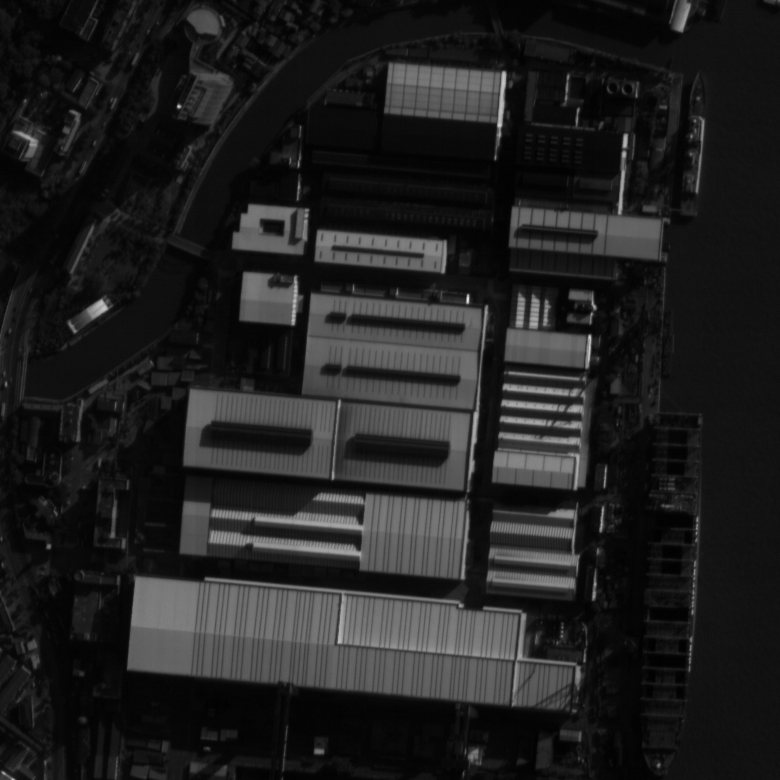

In [5]:
monochrome_image_path = project_directory / '11.bmp'
monochrome_image = np.array(Image.open(monochrome_image_path).convert('L'), dtype=np.uint8)[:, :, np.newaxis]
print('Исходное изображение')
display(Image.fromarray(monochrome_image[:, :, 0]))


## ЛР1. Инверсия изображения

Операция сохранена из ЛР1: заменить яркость каждого пикселя на 255 минус его исходное значение. Здесь показывается результат вызова сервера.


Инверсия


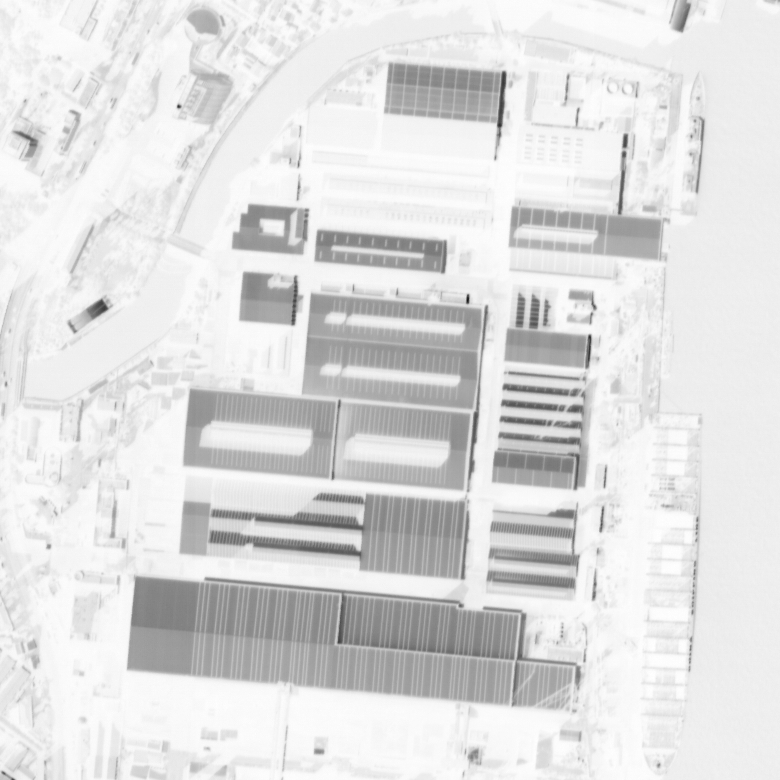

In [6]:
inverted_image = call_image_method('color_inversion', monochrome_image)
print('Инверсия')
display(Image.fromarray(inverted_image[:, :, 0]))


## ЛР1. Отражение изображения

Операция сохранена из ЛР1: отразить изображение относительно вертикальной оси, поменяв местами левую и правую стороны.


Отражение


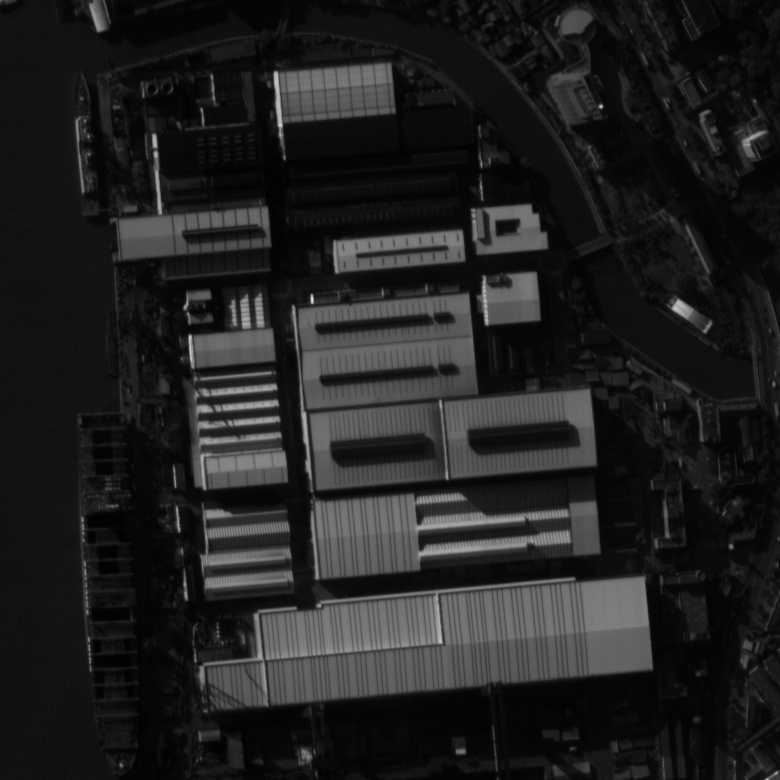

In [7]:
flipped_image = call_image_method('vertical_flip', monochrome_image)
print('Отражение')
display(Image.fromarray(flipped_image[:, :, 0]))


## ЛР1. Бинаризация изображения

Операция сохранена из ЛР1: пиксели с яркостью строго больше заданного порога сделать белыми, остальные — чёрными. Порог можно изменить перед запуском.


Бинаризация, порог 128


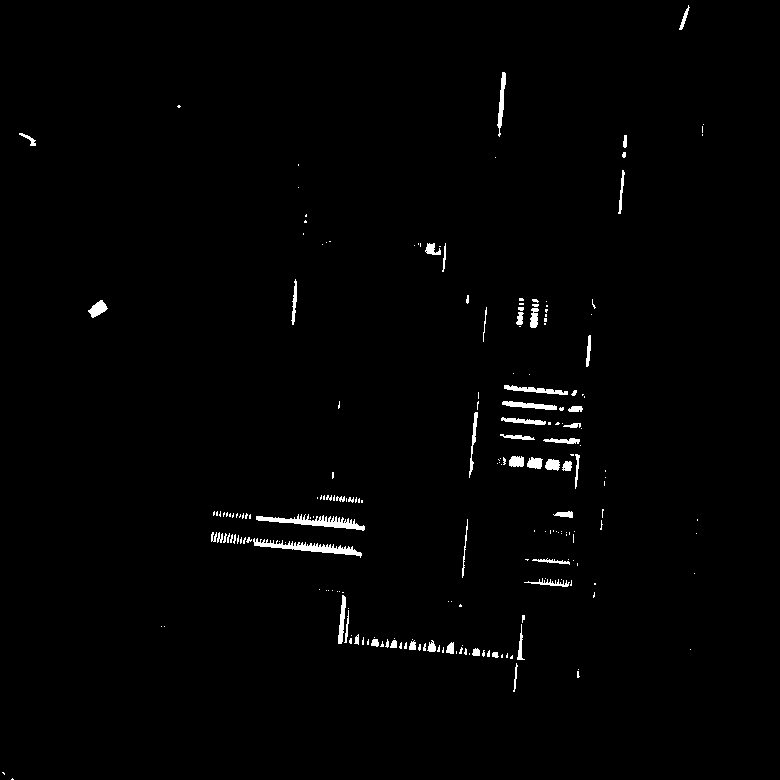

In [8]:
binarization_threshold = 128
binarized_image = call_image_method('binarize_image', monochrome_image, binarization_threshold)
print('Бинаризация, порог', binarization_threshold)
display(Image.fromarray(binarized_image[:, :, 0]))


## Задание 2. Бинаризация и процент пикселей выше порога

Требуется добавить новую серверную функцию: бинаризировать изображение и вернуть процент пикселей с яркостью строго больше порога. Здесь выводятся обработанное изображение и рассчитанный процент.


Бинаризация, порог 32
Пикселей выше порога: 26.99%


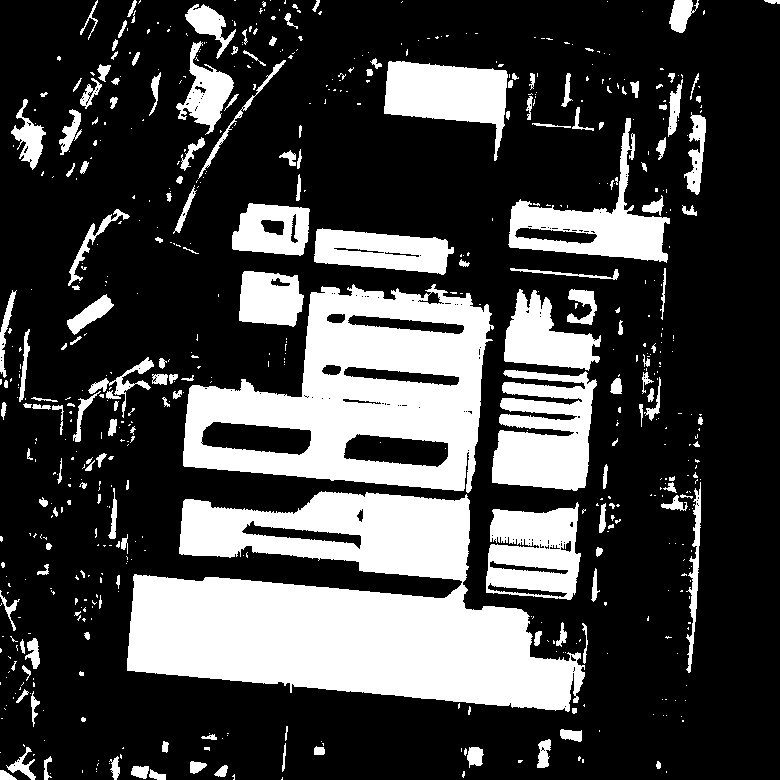

In [9]:
coverage_threshold = 32
coverage_binarization_result = main_service.binarize_with_coverage(pack_image(monochrome_image), coverage_threshold)
coverage_binarized_image = unpack_image(coverage_binarization_result['image'])
print('Бинаризация, порог', coverage_threshold)
display(Image.fromarray(coverage_binarized_image[:, :, 0]))
print('Пикселей выше порога: {:.2f}%'.format(coverage_binarization_result['above_threshold_percent']))


## Проверка цветного изображения

Методы ЛР1 должны сохранять поддержку RGB. Здесь тот же прокси обрабатывает
`Jellyfish.jpg`. Уменьшенные копии выводятся только для просмотра; сервер получает
исходный массив. Ожидаются инверсия, отражение и бинаризация цветного изображения.


Исходник RGB (768, 1024, 3)
Инверсия RGB (768, 1024, 3)
Отражение RGB (768, 1024, 3)
Бинаризация RGB (768, 1024, 3)


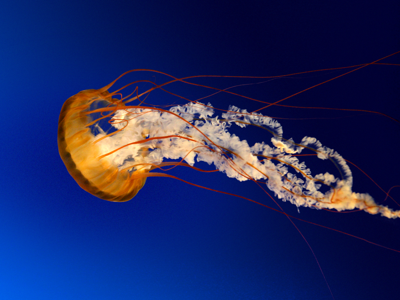

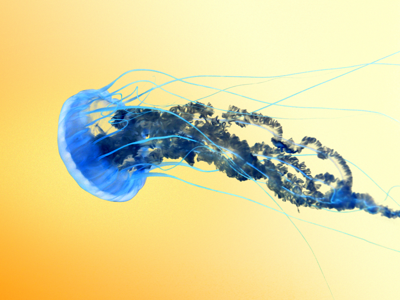

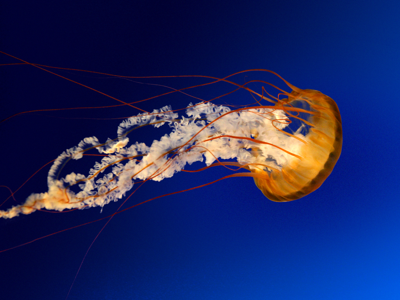

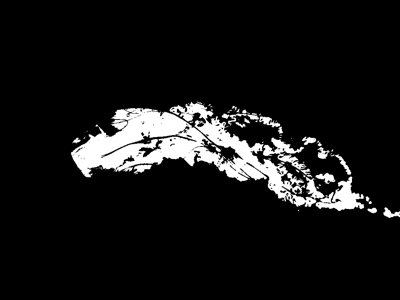

In [10]:
color_image = np.array(Image.open(project_directory / 'Jellyfish.jpg').convert('RGB'), dtype=np.uint8)
color_results = {
    'Исходник RGB': color_image,
    'Инверсия RGB': call_image_method('color_inversion', color_image),
    'Отражение RGB': call_image_method('vertical_flip', color_image),
    'Бинаризация RGB': call_image_method('binarize_image', color_image, 128),
}
for result_name, result_array in color_results.items():
    print(result_name, result_array.shape)
    preview = Image.fromarray(result_array)
    preview.thumbnail((400, 300))
    display(preview)


## Задание 3. Время вызова и длительность операции

Прокси передаёт события статистике. Здесь читается весь журнал SQLite.
В таблице должны быть время, имя операции и длительность в секундах.
Прямой запрос журнала не проходит через прокси и не создаёт новых событий.


In [11]:
all_events = statistics_service.get_events()
show_events(all_events)


Количество событий: 123


,id,timestamp,event_type,duration,details
0,1,2026-10-20 17:38:52,ping,0.003302,
1,2,2026-10-20 17:38:52,sum,0.003807,
2,3,2026-10-20 17:38:52,pow,0.002992,
3,4,2026-10-20 17:38:52,black_list_check,0.016032,
4,5,2026-10-20 17:38:52,black_list_check,0.007082,
5,6,2026-10-20 17:38:52,too_many_requests,0.000000,method=black_list_check
6,7,2026-10-20 17:38:57,black_list_check,0.006438,
7,8,2026-10-20 17:39:49,ping,0.009195,
8,9,2026-10-20 17:39:49,sum,0.002604,
9,10,2026-10-20 17:39:49,pow,0.002561,


## Задание 6. Фильтр по типу функции

Ожидаются только записи проверки чёрного списка. Все фильтры можно менять
и запускать повторно, как отдельные задания в клиенте ЛР2.


In [12]:
blacklist_events = statistics_service.get_events('black_list_check')
show_events(blacklist_events)


Количество событий: 15


,id,timestamp,event_type,duration,details
0,4,2026-10-20 17:38:52,black_list_check,0.016032,
1,5,2026-10-20 17:38:52,black_list_check,0.007082,
2,7,2026-10-20 17:38:57,black_list_check,0.006438,
3,11,2026-10-20 17:39:49,black_list_check,0.015055,
4,12,2026-10-20 17:39:49,black_list_check,0.008792,
5,14,2026-10-20 17:39:54,black_list_check,0.007145,
6,58,2026-10-20 17:41:55,black_list_check,0.014381,
7,59,2026-10-20 17:41:55,black_list_check,0.006627,
8,61,2026-10-20 17:42:00,black_list_check,0.009590,
9,81,2026-10-28 16:31:50,black_list_check,0.016472,


## Задание 6. Фильтр по времени вызова

Выбираются события за сегодняшний день до текущего момента.
Время задаётся в формате YYYY-MM-DD HH:MM:SS, обе границы включаются.


In [13]:
filter_start_time = datetime.now().strftime('%Y-%m-%d 00:00:00')
filter_end_time = datetime.now().strftime('%Y-%m-%d %H:%M:%S')
time_events = statistics_service.get_events('', filter_start_time, filter_end_time)
show_events(time_events)


Количество событий: 46


,id,timestamp,event_type,duration,details
0,78,2026-10-28 16:31:49,ping,0.002920,
1,79,2026-10-28 16:31:49,sum,0.002737,
2,80,2026-10-28 16:31:50,pow,0.002413,
3,81,2026-10-28 16:31:50,black_list_check,0.016472,
4,82,2026-10-28 16:31:50,black_list_check,0.005978,
5,83,2026-10-28 16:31:50,too_many_requests,0.000000,method=black_list_check; pause_seconds=4.750000
6,84,2026-10-28 16:31:55,black_list_check,0.005602,
7,85,2026-10-28 16:31:55,color_inversion,0.841228,
8,86,2026-10-28 16:31:56,vertical_flip,0.495095,
9,87,2026-10-28 16:31:57,binarize_image,0.893151,


## Задание 6. Фильтр по длительности

Выбираются вызовы длительностью от 0 до 1 секунды включительно.
Время ожидания ограничения запросов в эту длительность не входит.


In [14]:
minimum_duration = 0.0
maximum_duration = 1.0
duration_events = statistics_service.get_events('', '', '', minimum_duration, maximum_duration)
show_events(duration_events)


Количество событий: 110


,id,timestamp,event_type,duration,details
0,1,2026-10-20 17:38:52,ping,0.003302,
1,2,2026-10-20 17:38:52,sum,0.003807,
2,3,2026-10-20 17:38:52,pow,0.002992,
3,4,2026-10-20 17:38:52,black_list_check,0.016032,
4,5,2026-10-20 17:38:52,black_list_check,0.007082,
5,6,2026-10-20 17:38:52,too_many_requests,0.000000,method=black_list_check
6,7,2026-10-20 17:38:57,black_list_check,0.006438,
7,8,2026-10-20 17:39:49,ping,0.009195,
8,9,2026-10-20 17:39:49,sum,0.002604,
9,10,2026-10-20 17:39:49,pow,0.002561,


## Задание 6. Совместное применение фильтров

Ожидаются только проверки чёрного списка в указанном временном диапазоне,
длительность которых не превышает одну секунду. Пустая строка отключает
текстовый фильтр, None отключает границу длительности.


In [15]:
combined_events = statistics_service.get_events(
    'black_list_check', filter_start_time, filter_end_time, 0.0, 1.0
)
show_events(combined_events)


Количество событий: 6


,id,timestamp,event_type,duration,details
0,81,2026-10-28 16:31:50,black_list_check,0.016472,
1,82,2026-10-28 16:31:50,black_list_check,0.005978,
2,84,2026-10-28 16:31:55,black_list_check,0.005602,
3,112,2026-10-28 16:33:53,black_list_check,0.014288,
4,113,2026-10-28 16:33:53,black_list_check,0.006606,
5,115,2026-10-28 16:33:58,black_list_check,0.006760,


## Задание 4. Ограничение 5 запросов за 5 секунд на 12 запросах

Сначала ждём освобождения окна после предыдущих заданий. Затем отправляем 12
быстрых ping без повторных попыток. Запросы 6 и 11 ожидают около пяти секунд,
остальные выполняются сразу. Все запросы должны вернуть True.

В консоли прокси выводится фактическая длительность каждой паузы. После ожидания
она сохраняется в details события too_many_requests как pause_seconds.
В клиенте показываются время каждого запроса и все новые записи из SQLite:
12 событий ping и события ограничения. При скользящем окне возможны также
короткие дополнительные паузы, пока освобождаются места следующих запросов.
Каждая такая пауза тоже выводится и сохраняется. Длительность операции duration
не включает ожидание; её нельзя путать с pause_seconds.
Запускайте демонстрацию без параллельных запросов других клиентов.


In [16]:
time.sleep(5)
events_before_limit = statistics_service.get_events()
last_event_id = max((event['id'] for event in events_before_limit), default=0)
request_results = []
for request_number in range(1, 13):
    started_at = time.perf_counter()
    result = main_service.ping()
    client_seconds = time.perf_counter() - started_at
    print(f'Запрос {request_number:2}: {result}, время клиента {client_seconds:.3f} с')
    request_results.append({
        'request': request_number,
        'result': result,
        'client_seconds': client_seconds,
    })
display(pd.DataFrame(request_results))
limit_events = [event for event in statistics_service.get_events() if event['id'] > last_event_id]
show_events(limit_events)

# Фактическая пауза читается из базы, отдельно от времени выполнения ping.
pause_events = [event for event in limit_events if event['event_type'] == 'too_many_requests']
pause_durations = []
for event in pause_events:
    pause_seconds = float(event['details'].split('pause_seconds=')[1])
    pause_durations.append(pause_seconds)
    print(f"Пауза из SQLite: {pause_seconds:.6f} с; {event['details']}")

limit_ok = (
    all(request['result'] for request in request_results)
    and len(pause_events) >= 2
    and sum(event['event_type'] == 'ping' for event in limit_events) == 12
    and all(pause > 0 for pause in pause_durations)
    and sum(pause >= 4.0 for pause in pause_durations) >= 2
    and request_results[5]['client_seconds'] >= 4.0
    and request_results[10]['client_seconds'] >= 4.0
)
print('Ограничение запросов:', 'OK' if limit_ok else 'Проверьте таблицу и настройки прокси')


Запрос  1: True, время клиента 0.018 с
Запрос  2: True, время клиента 0.016 с
Запрос  3: True, время клиента 0.016 с
Запрос  4: True, время клиента 0.015 с
Запрос  5: True, время клиента 0.038 с
Запрос  6: True, время клиента 4.985 с
Запрос  7: True, время клиента 0.024 с
Запрос  8: True, время клиента 0.032 с
Запрос  9: True, время клиента 0.017 с
Запрос 10: True, время клиента 0.015 с
Запрос 11: True, время клиента 4.927 с
Запрос 12: True, время клиента 0.033 с
Количество событий: 14
Пауза из SQLite: 4.906270 с; method=ping; pause_seconds=4.906270
Пауза из SQLite: 4.875543 с; method=ping; pause_seconds=4.875543
Ограничение запросов: OK


,request,result,client_seconds
0,1,True,0.017654
1,2,True,0.016395
2,3,True,0.016441
3,4,True,0.014630
4,5,True,0.038434
5,6,True,4.985059
6,7,True,0.024246
7,8,True,0.032081
8,9,True,0.016557
9,10,True,0.015168


,id,timestamp,event_type,duration,details
0,124,2026-10-28 16:34:17,ping,0.002960,
1,125,2026-10-28 16:34:17,ping,0.002958,
2,126,2026-10-28 16:34:17,ping,0.002594,
3,127,2026-10-28 16:34:17,ping,0.002622,
4,128,2026-10-28 16:34:17,ping,0.002607,
5,129,2026-10-28 16:34:17,too_many_requests,0.000000,method=ping; pause_seconds=4.906270
6,130,2026-10-28 16:34:22,ping,0.003049,
7,131,2026-10-28 16:34:22,ping,0.002479,
8,132,2026-10-28 16:34:22,ping,0.002937,
9,133,2026-10-28 16:34:22,ping,0.002758,


## Задание 5. Подготовка проверки выключенной статистики

Сохраняем количество записей перед остановкой сервиса. После перезапуска
старые записи должны остаться, а запрос при выключенной статистике не добавится.


In [17]:
events_before_outage = statistics_service.get_events()
print('Событий перед остановкой статистики:', len(events_before_outage))


Событий перед остановкой статистики: 137


## Задание 5. Основная операция без статистики

Остановите ядро тетради xmlrpc_stats2_server.ipynb или прервите её выполнение.
Основной сервер и прокси оставьте работающими. Теперь выполните следующую ячейку.
Ожидается сумма 5; прокси сообщит о пропущенном событии в своей тетради.


In [18]:
result_without_statistics = main_service.sum(2, 3)
print('Сумма при выключенной статистике:', result_without_statistics)
statistics_outage_ok = result_without_statistics == 5


Сумма при выключенной статистике: 5


## Задание 5. Сохранение SQLite после перезапуска

Перезапустите ядро статистики и снова выполните её серверную ячейку.
После запуска выполните следующую ячейку клиента. Ожидается полное совпадение
событий до и после остановки. Пропущенное событие не восстанавливается.


In [19]:
events_after_restart = statistics_service.get_events()
persistence_ok = events_after_restart == events_before_outage
print('Событий после перезапуска:', len(events_after_restart))
print('Сохранение журнала:', 'OK' if persistence_ok else 'Состав событий изменился')


Событий после перезапуска: 137
Сохранение журнала: OK


## Дополнительная проверка. Основной сервер недоступен

Остановите основной сервер xmlrpc_server.ipynb, оставив прокси и статистику.
Ожидается XML-RPC ошибка 503 с понятным сообщением; прокси запишет ошибку в журнал.


In [20]:
main_outage_ok = False
try:
    main_service.ping()
    print('Основной сервер ещё работает: остановите его и повторите ячейку.')
except xmlrpc.client.Fault as error:
    print('Код ошибки:', error.faultCode)
    print('Сообщение:', error.faultString)
    main_outage_ok = error.faultCode == 503
error_events = [event for event in statistics_service.get_events('ping')
                if event['details'].startswith('error:')]
show_events(error_events)


Код ошибки: 503
Сообщение: Основной сервер недоступен: [WinError 10061] Подключение не установлено, т.к. конечный компьютер отверг запрос на подключение
Количество событий: 0
По указанным условиям событий нет.


## Восстановление основного сервера и итог

Перезапустите ядро основного сервера и снова выполните его ячейку.
Прокси перезапускать не требуется. Ожидается успешный ping и OK для проверок.


In [21]:
restored_ping = main_service.ping()
checks = {
    'Базовые методы после восстановления': restored_ping is True,
    'Статусы чёрного списка': [exact_blacklist_result['status'], similar_blacklist_result['status'],
                              missing_blacklist_result['status']] == ['yes', 'similar', 'no'],
    'Инверсия монохромного изображения': np.array_equal(inverted_image, 255 - monochrome_image),
    'Отражение монохромного изображения': np.array_equal(flipped_image, monochrome_image[:, ::-1, :]),
    'Ограничение запросов': limit_ok,
    'Работа без статистики': statistics_outage_ok,
    'Сохранение SQLite': persistence_ok,
    'Ошибка при выключенном основном сервере': main_outage_ok,
}
for check_name, passed in checks.items():
    print(('OK: ' if passed else 'FAIL: ') + check_name)
print('ИТОГ:', 'все проверки ЛР3 пройдены' if all(checks.values()) else 'есть непройденные проверки')


OK: Базовые методы после восстановления
OK: Статусы чёрного списка
OK: Инверсия монохромного изображения
OK: Отражение монохромного изображения
OK: Ограничение запросов
OK: Работа без статистики
OK: Сохранение SQLite
OK: Ошибка при выключенном основном сервере
ИТОГ: все проверки ЛР3 пройдены


## Репозиторий GitHub

Работа опубликована в публичном репозитории [Kromobot/RSOI](https://github.com/Kromobot/RSOI).
В истории сохранены исходное состояние ЛР2, реализация ЛР3 и доработки.
Требование минимум двух коммитов выполнено. Историю можно посмотреть
на GitHub или командой `git log --oneline` в папке LR3.
